# Do calendar and prior-year weather help with each model’s best lookback?

这个notebook是notebook02的延伸，每个模型都使用notebook 1中验证集RMSE最优的近期天气回看窗口；其他部分沿用notebook02的设置，比较加入历史同期天气和日历特征后的变化。

| Input setting | Information for one target date |
|---|---|
| Recent only | Each model’s selected number of consecutive days before the target date |
| Calendar only | Sine and cosine of the target date’s annual phase |
| Recent + calendar | Recent weather and calendar pairs for recent days and the target |
| History + calendar | Seven days around the same date in each of five prior years, with calendar pairs, plus the target calendar |
| History only | The same 35 prior-year weather days |
| Recent + history | Recent weather and the 35 prior-year weather days |
| Recent + history + calendar | Both weather windows and calendar pairs for all input dates and the target |

### Results for every model

Mean validation RMSE in °C over the same five chronological folds as Notebook 2. Lower is better. The temperature-only baseline uses its own selected lookback in every column.

| Model | Lookback (days) | Recent only | Calendar only | Recent + calendar | History + calendar | History only | Recent + history | All inputs |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Baseline | 15 | 3.192 | 3.192 | 3.192 | 3.192 | 3.192 | 3.192 | 3.192 |
| LinearRegression | 2 | 2.690 | 4.153 | 2.697 | 12.282 | 10.938 | 5.965 | 5.748 |
| Ridge | 2 | 2.687 | 4.153 | 2.692 | 7.580 | 7.367 | 5.141 | 5.307 |
| KNN | 1 | 3.339 | 4.632 | 3.170 | 4.581 | 4.894 | 4.785 | 4.486 |
| Lasso | 5 | 2.730 | 4.153 | 2.726 | 5.435 | 5.491 | 3.361 | 3.357 |
| ElasticNet | 5 | 2.731 | 4.153 | 2.732 | 5.636 | 5.693 | 3.532 | 3.523 |
| SVR | 4 | 2.717 | 4.172 | 2.694 | 5.240 | 5.426 | 3.469 | 3.495 |
| NN | 2 | 2.654 | 4.185 | 2.595 | 4.890 | 5.083 | 3.650 | 3.611 |
| RandomForest | 2 | 2.769 | 4.594 | 2.730 | 4.432 | 4.463 | 2.962 | 2.976 |
| Poly | 1 | 6.107 | 4.169 | 13.681 | 5.108 | 5.221 | 4.662 | 4.597 |
| Poly Ridge | 2 | 3.031 | 5.525 | 2.863 | 5.067 | 5.180 | 4.380 | 4.354 |
| Poly Lasso | 5 | 2.719 | 4.165 | 2.684 | 4.641 | 4.799 | 2.958 | 2.942 |

Lowest measured validation error: **NN**, **Recent + calendar**, **2.595°C**.

In [1]:
from pathlib import Path
import sys

# Launch from the project root or this subfolder.
here = Path.cwd()
if not (here / "experiments.py").exists():
    here = here / "regression_inputs"
sys.path.insert(0, str(here.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from experiments import Inputs, MODELS, SETTINGS, best_lookbacks, evaluate, summarize

# Saved scores refer to this exact weather file.
from hashlib import sha256
from experiments import DATA
if sha256(DATA.read_bytes()).hexdigest() != "e1ac9e85c904d3b35bfcc4ee3bb30d8e8e47a7f78d76454ebcc5b9586dd71ea5":
    print("Weather CSV changed. Refit every model before comparing with the saved scores.")

part = 3
study = Inputs(part)
saved = pd.read_csv(here / "validation_folds.csv")
lookbacks = best_lookbacks(saved)
model_inputs = {model: Inputs(part, recent_days=int(days))
                for model, days in lookbacks.items()}
# False displays the committed measurements. True runs every missing fold.
RUN_FULL = False
# Limit this list to one family for a smaller new run.
MODELS_TO_FIT = MODELS.copy()
RUN_SELECTED_TEST = False
print("All model entries:", ", ".join(MODELS))
print(f"{len(study.dates):,} targets, {study.dates[0].date()} through {study.dates[-1].date()}")
print("First test date:", study.test_start.date())

All model entries: Baseline, LinearRegression, Ridge, KNN, Lasso, ElasticNet, SVR, NN, RandomForest, Poly, Poly Ridge, Poly Lasso
5,112 targets, 2011-01-04 through 2025-01-01
First test date: 2021-03-17


### Check the calendar alignment

Each seven-day historical window belongs to an earlier year. The first dates can fall in December when the target is in early January.

In [2]:
example = study.dates.get_loc("2025-01-01")
windows = [[i + 1, study.history[7*i][example].date(), study.history[7*i + 6][example].date()]
           for i in range(5)]
display(pd.DataFrame(windows, columns=["Years earlier", "Window start", "Window end"]))
assert windows[0][1] == pd.Timestamp("2023-12-29").date()
assert windows[0][2] == pd.Timestamp("2024-01-04").date()
assert study.history[-1][example] < study.dates[example]
assert study.test_start == pd.Timestamp("2021-03-17")

,Years earlier,Window start,Window end
0,1,2023-12-29,2024-01-04
1,2,2022-12-29,2023-01-04
2,3,2021-12-29,2022-01-04
3,4,2020-12-29,2021-01-04
4,5,2019-12-29,2020-01-04


### Which dates train and validate each model?

In [3]:
splits = []
for fold, (train, valid) in enumerate(study.splits(), start=1):
    splits.append([fold, len(train), study.dates[train[0]].date(), study.dates[train[-1]].date(),
                   len(valid), study.dates[valid[0]].date(), study.dates[valid[-1]].date()])
display(pd.DataFrame(splits, columns=["Fold", "Train days", "Train start", "Train end",
                                      "Validation days", "Validation start", "Validation end"]))

,Fold,Train days,Train start,Train end,Validation days,Validation start,Validation end
0,1,625,2011-01-04,2012-09-19,620,2012-09-20,2014-06-01
1,2,1245,2011-01-04,2014-06-01,620,2014-06-02,2016-02-11
2,3,1865,2011-01-04,2016-02-11,620,2016-02-12,2017-10-23
3,4,2485,2011-01-04,2017-10-23,620,2017-10-24,2019-07-05
4,5,3105,2011-01-04,2019-07-05,620,2019-07-06,2021-03-16


### Model and scoring conventions

依旧使用main.ipynb中相同的模型lineup和参数；

近期窗口按notebook 1的验证分数选定，若并列则选较短的窗口；每种模型在所有含近期天气的组合里使用同一个窗口。

Notebook 1 and Notebook 3 share some validation dates. Use these results to compare settings after lookback selection. Use the reserved dates to estimate performance after choosing a model and input setting.

For the weather models, Calendar only, History only, and History + calendar reuse Notebook 2’s fold scores because their inputs and folds match exactly.

In [4]:
scores = saved.loc[saved.part.eq(part)].copy()
if RUN_FULL:
    fresh_rows = []
    for setting in study.settings:
        print(f"Evaluating {setting} ...", flush=True)
        for model in MODELS_TO_FIT:
            fresh_rows.append(evaluate(model_inputs[model], [model], [setting]))
            print(f"  {model} complete", flush=True)
    fresh = pd.concat(fresh_rows, ignore_index=True)
    scores = pd.concat([scores.loc[~scores.model.isin(MODELS_TO_FIT)], fresh], ignore_index=True)

summary = summarize(scores)
assert summary.folds.eq(5).all()
# Only complete five-fold comparisons enter this table.
errors = summary.pivot(index="setting", columns="model", values="cv_rmse").reindex(
    index=study.settings, columns=MODELS)
print(f"{int(errors.notna().sum().sum())} of {errors.size} setting/model pairs scored.")
print("Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.")
display(errors.rename(index={"Recent 28": "Recent only"}).round(3))
warnings_seen = summary.loc[summary.convergence_warning, ["model", "setting"]]
if len(warnings_seen):
    print("Inspect convergence warnings before interpreting:", warnings_seen.values.tolist())

84 of 84 setting/model pairs scored.
Mean validation RMSE (°C), smaller is better. A dash indicates an unmeasured combination.
Inspect convergence warnings before interpreting: [['ElasticNet', 'History + calendar'], ['ElasticNet', 'History only'], ['ElasticNet', 'Recent + history'], ['ElasticNet', 'Recent + history + calendar'], ['NN', 'Recent 28'], ['NN', 'Calendar only'], ['NN', 'Recent + calendar'], ['Poly Lasso', 'History + calendar']]


model,Baseline,LinearRegression,Ridge,KNN,Lasso,ElasticNet,SVR,NN,RandomForest,Poly,Poly Ridge,Poly Lasso
setting,,,,,,,,,,,,
Recent only,3.192,2.690,2.687,3.339,2.730,2.731,2.717,2.654,2.769,6.107,3.031,2.719
Calendar only,3.192,4.153,4.153,4.632,4.153,4.153,4.172,4.185,4.594,4.169,5.525,4.165
Recent + calendar,3.192,2.697,2.692,3.170,2.726,2.732,2.694,2.595,2.730,13.681,2.863,2.684
History + calendar,3.192,12.282,7.580,4.581,5.435,5.636,5.240,4.890,4.432,5.108,5.067,4.641
History only,3.192,10.938,7.367,4.894,5.491,5.693,5.426,5.083,4.463,5.221,5.180,4.799
Recent + history,3.192,5.965,5.141,4.785,3.361,3.532,3.469,3.650,2.962,4.662,4.380,2.958
Recent + history + calendar,3.192,5.748,5.307,4.486,3.357,3.523,3.495,3.611,2.976,4.597,4.354,2.942


### How do the seven input settings compare?

Each panel shows the seven settings for one model. The vertical scale can differ by panel. Use the table above for exact cross-model comparisons. The paired differences below compare forecasts from the same validation dates.

The last table subtracts Notebook 2’s fixed-window RMSE from this notebook’s model-specific RMSE on the same folds. Negative values mean the model-specific window helped.

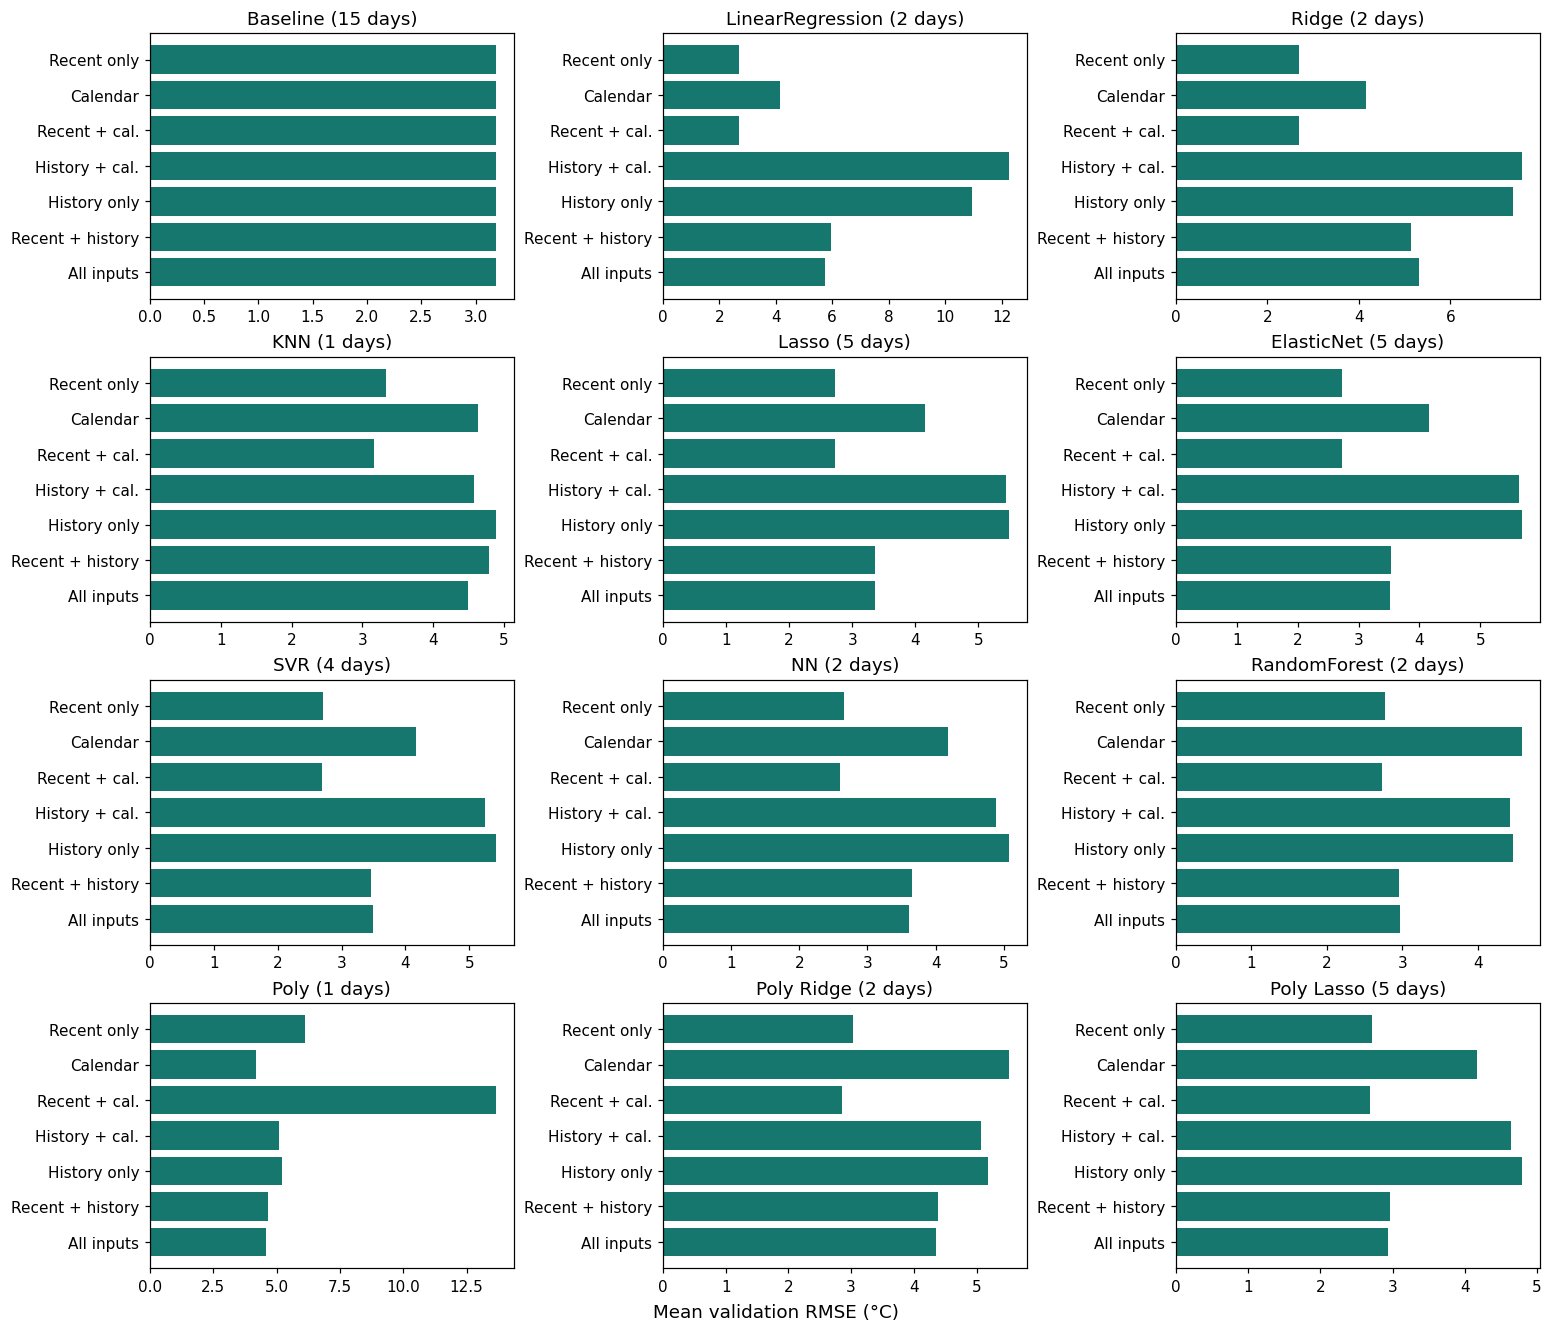

,Add history to recent,Add calendar to history,Add calendar to recent + history,Add calendar to recent,Add history to recent + calendar,Add recent to history + calendar
model,,,,,,
Baseline,0.000,0.000,0.000,0.000,0.000,0.000
ElasticNet,0.800,-0.057,-0.009,0.001,0.791,-2.113
KNN,1.446,-0.313,-0.299,-0.168,1.316,-0.094
Lasso,0.632,-0.056,-0.004,-0.003,0.631,-2.078
LinearRegression,3.275,1.344,-0.217,0.007,3.051,-6.534
NN,0.996,-0.194,-0.040,-0.059,1.015,-1.279
Poly,-1.445,-0.113,-0.066,7.574,-9.085,-0.511
Poly Lasso,0.239,-0.158,-0.016,-0.035,0.258,-1.699
Poly Ridge,1.348,-0.113,-0.026,-0.169,1.491,-0.713


,Add history to recent,Add calendar to history,Add calendar to recent + history,Add calendar to recent,Add history to recent + calendar,Add recent to history + calendar
fold,,,,,,
1,9.347,0.899,0.679,0.013,10.013,-3.886
2,1.427,-0.116,0.020,-0.010,1.457,-2.274
3,0.599,0.037,0.023,0.014,0.609,-1.803
4,0.528,0.181,0.057,0.009,0.576,-1.859
5,0.370,0.067,0.049,0.001,0.417,-1.545


setting,Recent only,Calendar only,Recent + calendar,History + calendar,History only,Recent + history,Recent + history + calendar
model,,,,,,,
Baseline,-0.014,-0.014,-0.014,-0.014,-0.014,-0.014,-0.014
ElasticNet,-0.413,0.000,-0.413,0.000,0.000,-0.351,-0.360
KNN,-0.902,0.000,-1.029,0.000,0.000,0.283,0.103
Lasso,-0.326,0.000,-0.328,0.000,0.000,-0.245,-0.248
LinearRegression,-1.151,0.000,-1.572,0.000,0.000,-0.552,-11.834
NN,-0.772,0.000,-0.827,0.000,0.000,-0.196,-0.277
Poly,1.654,0.000,9.204,0.000,0.000,0.337,0.236
Poly Lasso,-0.096,0.000,-0.133,0.000,0.000,0.054,0.038
Poly Ridge,-1.266,0.000,-1.469,0.000,0.000,0.178,0.099


In [5]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12), constrained_layout=True)
labels = ["Recent only", "Calendar", "Recent + cal.", "History + cal.", "History only", "Recent + history", "All inputs"]
for ax, model in zip(axes.flat, MODELS):
    ax.barh(labels, errors.loc[SETTINGS, model], color="#16776f")
    ax.invert_yaxis()
    ax.set_title(f"{model} ({lookbacks[model]} days)")
fig.supxlabel("Mean validation RMSE (°C)")
plt.show()

paired = scores.pivot(index=["model", "fold"], columns="setting", values="rmse")
delta = pd.DataFrame({
    "Add history to recent": paired["Recent + history"] - paired["Recent 28"],
    "Add calendar to history": paired["History + calendar"] - paired["History only"],
    "Add calendar to recent + history": paired[SETTINGS[-1]] - paired["Recent + history"],
    "Add calendar to recent": paired["Recent + calendar"] - paired["Recent 28"],
    "Add history to recent + calendar": paired[SETTINGS[-1]] - paired["Recent + calendar"],
    "Add recent to history + calendar": paired[SETTINGS[-1]] - paired["History + calendar"]})
display(delta.groupby(level="model").mean().dropna(how="all").round(3))
display(delta.xs("Ridge").round(3))
# Match model, setting and fold before comparing with Notebook 2.
fixed = saved.loc[saved.part.eq(2)].set_index(["model", "setting", "fold"])
specific = scores.set_index(["model", "setting", "fold"])
change = (specific.rmse - fixed.rmse).groupby(["model", "setting"]).mean().unstack()
display(change[SETTINGS].rename(columns={"Recent 28": "Recent only"}).round(3))

### What the full comparison shows

Using each model’s selected lookback lowered RMSE for **10 of 11** weather models in the recent-only setting compared with the fixed 28-day window. Adding prior-year weather to recent weather lowered RMSE for **1 of 11** variants. Adding just calendar features to recent weather lowered RMSE for **7 of 11**.

The lowest validation RMSE was **2.595°C** for **NN** using **Recent + calendar**, with a **2-day** lookback wherever recent weather is included.

### Final score on the reserved dates

In [6]:
if RUN_SELECTED_TEST:
    if errors.isna().any().any():
        raise ValueError("Complete the comparison with RUN_FULL=True before selecting by validation.")
    # Each model's input design is selected on validation only.
    selected = {model: errors[model].idxmin() for model in MODELS}
    held = pd.concat([evaluate(model_inputs[model], [model], [setting], test=True)
                      for model, setting in selected.items()], ignore_index=True)
    display(held.groupby(["model", "setting"]).agg(test_rmse=("rmse", "mean"),
            mae=("mae", "mean"), seeds=("seed", "nunique")).round(3))
else:
    print("Holdout scoring is off. Validation determines the preferred inputs.")

Holdout scoring is off. Validation determines the preferred inputs.
